### **Naive Bayes End-to-End ML Pipeline — Group Lab (3 Members)**

**Goal:** As a group of **3**, build a complete pipeline that predicts Titanic passenger survival with **Naive Bayes** — from raw data all the way to a final, evaluated model. The lab is split into **3 parts**, one per group member, but **everyone should read and understand every part** — you'll need each other's outputs to finish the pipeline.

**Dataset:** We'll use `seaborn`'s **built-in** Titanic dataset — no download or upload needed:
```python
titanic = sns.load_dataset('titanic')
```
(If your instructor asks you to use a different/self-generated dataset instead, the same structure below still applies — just swap the loading step.)

**How the 3 parts connect (the pipeline, in order):**

| Part | Member | Focus | Concepts Covered |
|---|---|---|---|
| **1** | **A** | Explore the raw data | EDA, Data Visualization, Bayes' Theorem (by hand) |
| **2** | **B** | Clean & transform the data | Missing Values, Binning, Binarization, Ordinal/One-Hot/Label Encoding, Column Transformer, Function/Power Transformer, Standardization & Normalization |
| **3** | **C** | Build & evaluate the model | Naive Bayes (from scratch + `sklearn`), Cross-Validation, Evaluation Metrics |

**Rule:** Member B's final output (`X_train_final`, `X_test_final`, `y_train`, `y_test`) is exactly what Member C needs as input. Member A's Section 1.7 (Bayes' Theorem by hand) is the conceptual foundation Member C will re-use in Section 3.1. **Talk to each other before starting your part.**

Cells marked `# TODO` are where you write your own code. Everything else (imports, structure, explanations) is provided to keep the group in sync.

#### **0. Shared Setup (Everyone Runs This First)**

Run this section before splitting into your parts — it loads the libraries and the dataset every part depends on.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set(style='whitegrid')


In [2]:
# Built-in dataset - no download required
titanic = sns.load_dataset('titanic')
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**A quick look at what we're working with:** each row is one passenger. Key columns: `survived` (target, 0/1), `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`, `who`, `alive` (text version of `survived`), `deck` (mostly missing).

#### **Part 1 (Member A): Exploratory Data Analysis & Bayes' Theorem Foundations**

**Your job:** understand the raw data before anyone touches it — its shape, quality issues, and the patterns that make Naive Bayes a sensible model choice here.

**1.1 Dataset Structure**

Check the shape, column data types, and general info of `titanic`.

In [3]:
# TODO: print the shape of the dataset
print("Dataset shape:", titanic.shape)

# TODO: use .info() to see column dtypes and non-null counts
titanic.info()



Dataset shape: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


**1.2 Statistical Summary**

`.describe()` gives count/mean/std/min/max/quartiles for numeric columns — a first look at scale and possible skew (e.g., compare `fare`'s mean vs its median/50%).

In [4]:
# TODO: call .describe() on titanic
titanic.describe()



,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**1.3 Missing Value Analysis**

Which columns have missing data, and how much? This will guide Member B's cleaning strategy in Part 2.

Missing values in each column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing values percentage:
survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


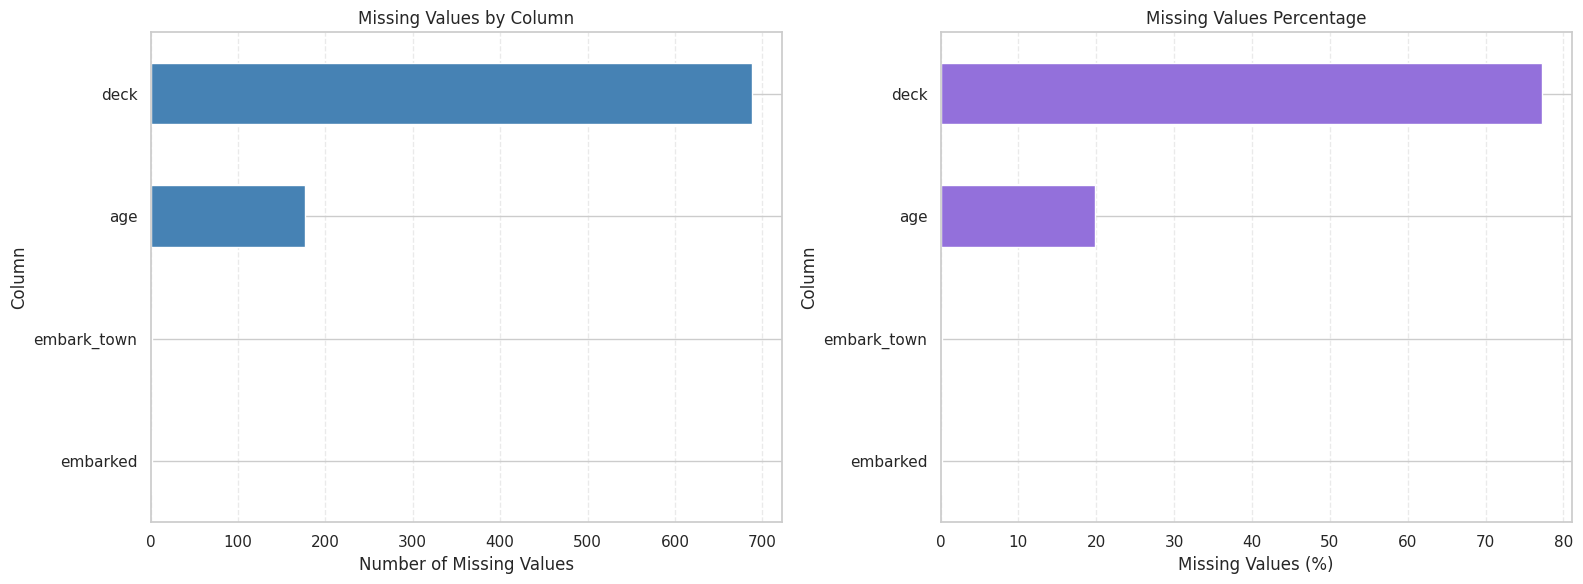

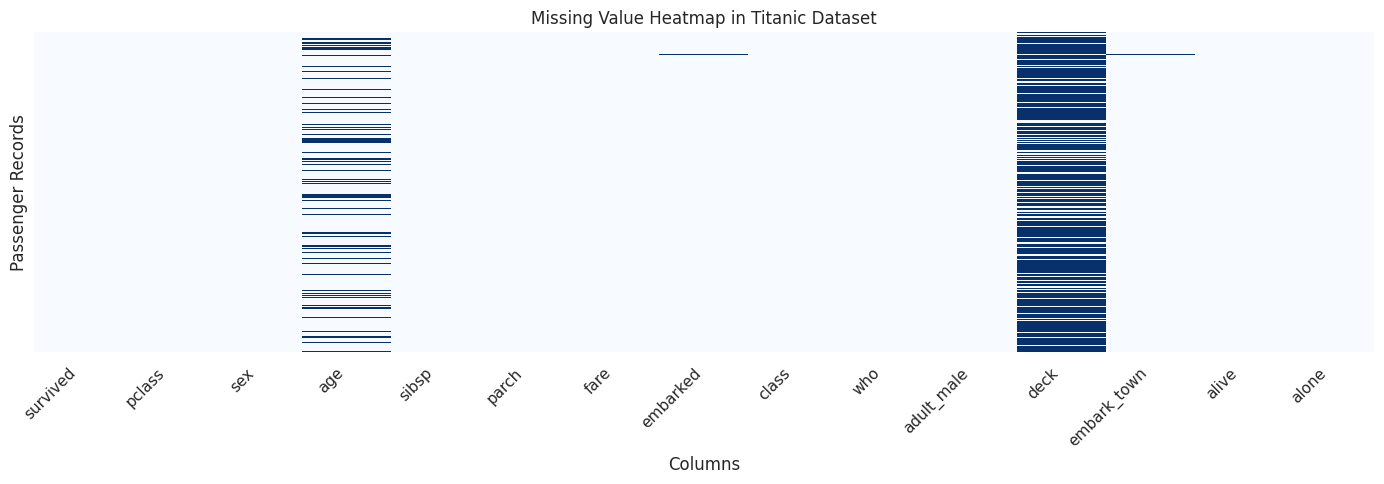

In [6]:
# TODO: compute titanic.isnull().sum()
missing_count = titanic.isnull().sum()
print("Missing values in each column:")
print(missing_count)

# TODO: also compute it as a percentage of total rows
missing_percentage = (titanic.isnull().sum() / len(titanic)) * 100
print("\nMissing values percentage:")
print(missing_percentage.round(2))

# TODO (visualization): plot a heatmap of missing values, e.g.
# sns.heatmap(titanic.isnull(), cbar=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Missing values count
missing_count[missing_count > 0].sort_values().plot(
    kind='barh',
    ax=axes[0],
    color='steelblue'
)
axes[0].set_title('Missing Values by Column')
axes[0].set_xlabel('Number of Missing Values')
axes[0].set_ylabel('Column')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

# Missing values percentage
missing_percentage[missing_percentage > 0].sort_values().plot(
    kind='barh',
    ax=axes[1],
    color='mediumpurple'
)
axes[1].set_title('Missing Values Percentage')
axes[1].set_xlabel('Missing Values (%)')
axes[1].set_ylabel('Column')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Missing values heatmap
plt.figure(figsize=(14, 5))
sns.heatmap(
    titanic.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='Blues'
)
plt.title('Missing Value Heatmap in Titanic Dataset')
plt.xlabel('Columns')
plt.ylabel('Passenger Records')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**1.4 Target Variable Distribution**

Is `survived` balanced or imbalanced? This matters for how we should judge "accuracy" later in Part 3.

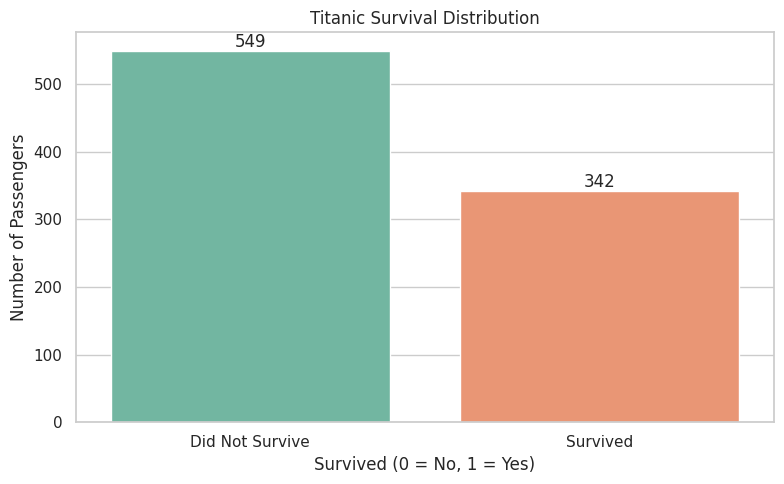

Survival percentage split:
survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [7]:
# TODO: sns.countplot the 'survived' column
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=titanic, x='survived', hue='survived', palette='Set2', legend=False)

plt.title('Titanic Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

# TODO: print the exact percentage split (value_counts(normalize=True))
print("Survival percentage split:")
print((titanic['survived'].value_counts(normalize=True) * 100).round(2))

**1.5 Univariate Analysis**

Look at `age` and `fare` individually — shape of distribution, and whether they look skewed (relevant for Member B's transformation step later).

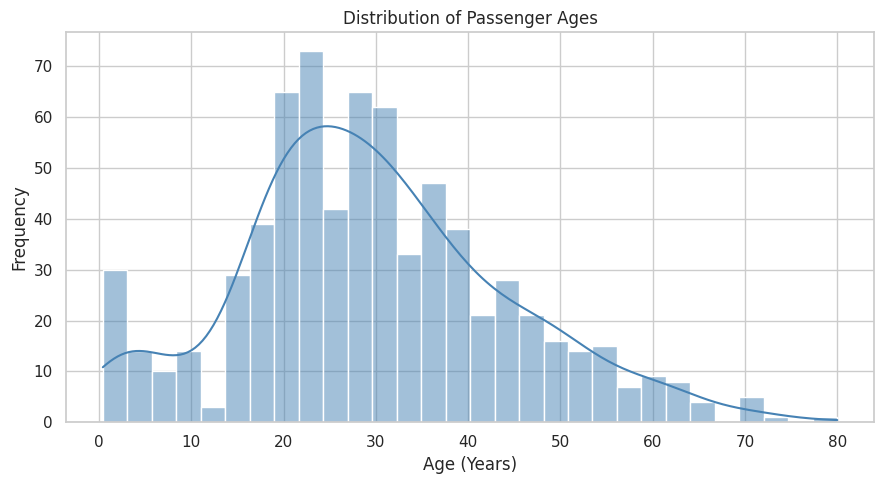

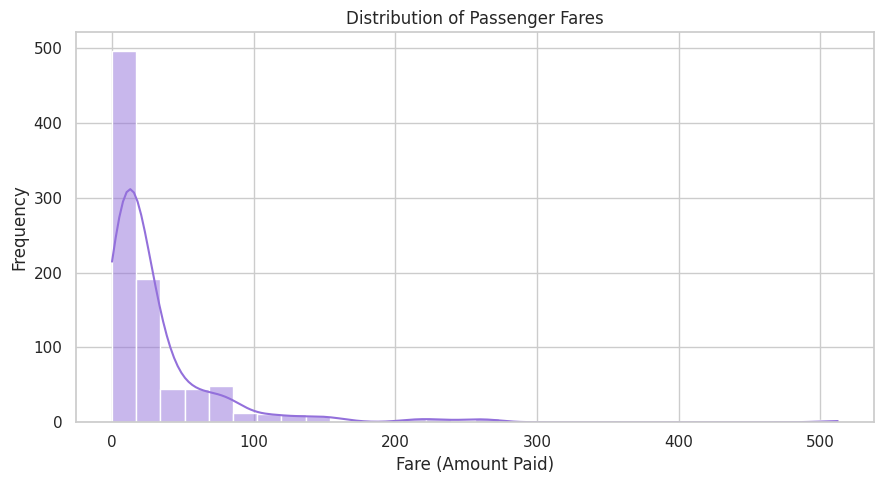

Age skewness: 0.38910778230082704
Fare skewness: 4.787316519674893


In [8]:
# TODO: plot a histogram (with KDE) of 'age'
plt.figure(figsize=(9, 5))
sns.histplot(data=titanic, x='age', kde=True, bins=30, color='steelblue')
plt.title('Distribution of Passenger Ages')
plt.xlabel('Age (Years)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# TODO: plot a histogram (with KDE) of 'fare'
plt.figure(figsize=(9, 5))
sns.histplot(data=titanic, x='fare', kde=True, bins=30, color='mediumpurple')
plt.title('Distribution of Passenger Fares')
plt.xlabel('Fare (Amount Paid)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# TODO: print titanic['age'].skew() and titanic['fare'].skew()
print("Age skewness:", titanic['age'].skew())
print("Fare skewness:", titanic['fare'].skew())

**1.6 Bivariate Analysis — Does Survival Depend on Sex and Class?**

Compute and visualize survival rate broken down by `sex`, and separately by `pclass`.

Survival Rate by Sex:
sex
female    74.20
male      18.89
Name: survived, dtype: float64

Survival Rate by Passenger Class:
pclass
1    62.96
2    47.28
3    24.24
Name: survived, dtype: float64


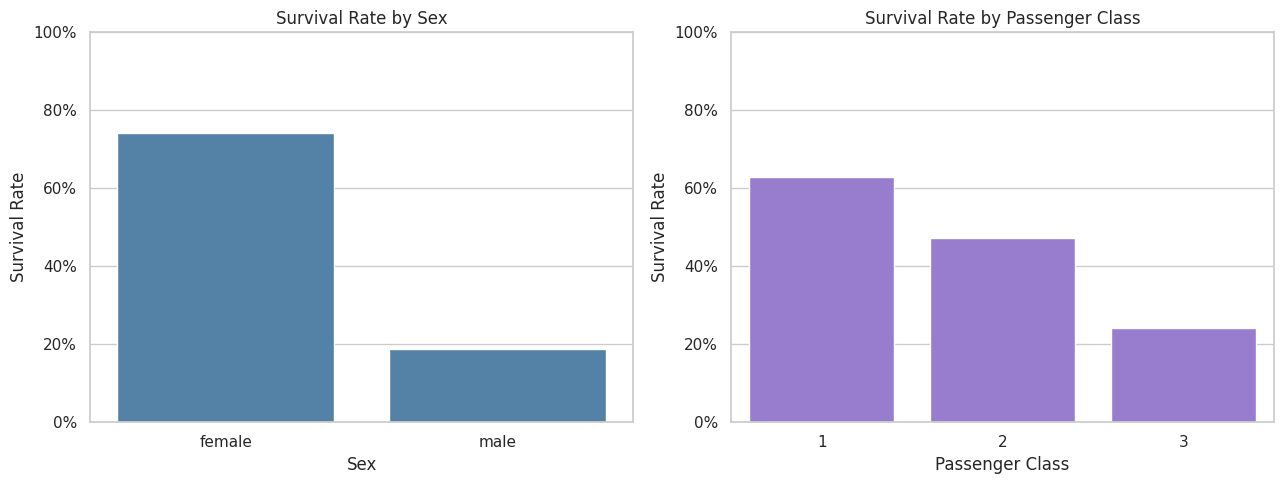

In [9]:
# TODO: titanic.groupby('sex')['survived'].mean()
sex_survival = titanic.groupby('sex')['survived'].mean()
print("Survival Rate by Sex:")
print((sex_survival * 100).round(2))

# TODO: titanic.groupby('pclass')['survived'].mean()
class_survival = titanic.groupby('pclass')['survived'].mean()
print("\nSurvival Rate by Passenger Class:")
print((class_survival * 100).round(2))

# TODO: visualize both with sns.barplot or sns.catplot

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x=sex_survival.index, y=sex_survival.values, ax=axes[0], color='steelblue')
axes[0].set_title('Survival Rate by Sex')
axes[0].set_xlabel('Sex')
axes[0].set_ylabel('Survival Rate')
axes[0].set_ylim(0, 1)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

sns.barplot(x=class_survival.index, y=class_survival.values, ax=axes[1], color='mediumpurple')
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_xlabel('Passenger Class')
axes[1].set_ylabel('Survival Rate')
axes[1].set_ylim(0, 1)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.show()



**1.7 Connecting to Bayes' Theorem**

Recall **Bayes' Theorem**:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

Let's estimate, **by hand**, the probability a passenger survived *given* they were female — i.e. $P(\text{Survived}=1 \mid \text{Sex}=\text{female})$ — using only priors and likelihoods computed from the data (not `groupby` directly), and then check it against the true empirical value from Section 1.6.

- $P(A) = P(\text{Survived}=1)$ → the overall survival rate
- $P(B) = P(\text{Sex}=\text{female})$ → the overall proportion of female passengers
- $P(B \mid A) = P(\text{Sex}=\text{female} \mid \text{Survived}=1)$ → among survivors, what fraction were female?

In [10]:
# TODO: P_A = P(Survived = 1)          -> titanic['survived'].mean()
P_A = titanic['survived'].mean()

# TODO: P_B = P(Sex = female)             -> (titanic['sex'] == 'female').mean()
P_B = (titanic['sex'] == 'female').mean()

# TODO: P_B_given_A = P(Sex=female | Survived=1)
#       hint: filter titanic where survived == 1, then compute the fraction that are female
survivors = titanic[titanic['survived'] == 1]
P_B_given_A = (survivors['sex'] == 'female').mean()

# TODO: apply Bayes' Theorem: P_A_given_B = (P_B_given_A * P_A) / P_B
P_A_given_B = (P_B_given_A * P_A) / P_B

# TODO: print P_A_given_B and compare it to titanic.groupby('sex')['survived'].mean()['female'] from Section 1.6
# They should match (up to rounding) - if not, recheck your probabilities above!
true_empirical_value = titanic.groupby('sex')['survived'].mean()['female']

print("P(A) - Overall survival probability:", round(P_A, 4))
print("P(B) - Probability of being female:", round(P_B, 4))
print("P(B|A) - Probability of being female given survival:", round(P_B_given_A, 4))
print("\nBayes' Theorem result:", round(P_A_given_B, 4))
print("Actual female survival rate:", round(true_empirical_value, 4))
print("Match:", np.isclose(P_A_given_B, true_empirical_value))


P(A) - Overall survival probability: 0.3838
P(B) - Probability of being female: 0.3524
P(B|A) - Probability of being female given survival: 0.6813

Bayes' Theorem result: 0.742
Actual female survival rate: 0.742
Match: True


**💡 Why this matters:** Naive Bayes classifiers work by applying exactly this formula to **every feature**, multiplying the likelihoods together under the "naive" independence assumption — Member C will build on this in Part 3.

**Hand off to Member B:** the raw `titanic` DataFrame, plus your findings on which columns are missing and which numeric columns are skewed.

#### **Part 2 (Member B): Data Cleaning, Transformation & Encoding**

**Your job:** take the raw `titanic` DataFrame and Member A's findings, and produce a fully cleaned, encoded, scaled, model-ready `X_train_final` / `X_test_final`.

**2.1 Selecting Columns and Splitting Train/Test First**

We split **before** cleaning so every fitted step (imputer, encoder, scaler) is learned only from `X_train` — this avoids **data leakage** into the test set.

In [11]:
from sklearn.model_selection import train_test_split

# Keep a focused set of columns for this lab
cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'survived']
df = titanic[cols].copy()

# TODO: X = df.drop(columns=['survived']), y = df['survived']
X = df.drop(columns=['survived'])
y = df['survived']

# TODO: train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#       name the results X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (712, 7)
X_test shape: (179, 7)
y_train shape: (712,)
y_test shape: (179,)


**2.2 Handling Missing Values**

From Part 1.3, `age` and `embarked` have missing values. Impute `age` with the **median** (robust to skew) and `embarked` with the **mode** (most frequent category) — fit on train, apply to both.

In [12]:
from sklearn.impute import SimpleImputer

# TODO: num_imputer = SimpleImputer(strategy='median')
num_imputer = SimpleImputer(strategy='median')

# TODO: fit num_imputer on X_train[['age']], then transform both X_train and X_test 'age' column
X_train['age'] = num_imputer.fit_transform(X_train[['age']]).ravel()
X_test['age'] = num_imputer.transform(X_test[['age']]).ravel()

# TODO: cat_imputer = SimpleImputer(strategy='most_frequent')
cat_imputer = SimpleImputer(strategy='most_frequent')

# TODO: fit cat_imputer on X_train[['embarked']], then transform both X_train and X_test 'embarked' column
X_train['embarked'] = cat_imputer.fit_transform(X_train[['embarked']]).ravel()
X_test['embarked'] = cat_imputer.transform(X_test[['embarked']]).ravel()

# TODO: confirm no missing values remain with .isnull().sum()
print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

Missing values in X_train:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Missing values in X_test:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


**2.3 Binning — Creating an `age_group` Feature (Custom Binning)**

Convert continuous `age` into meaningful, ordered groups using domain knowledge — a **custom binning** approach, with edges we choose ourselves:

`Child (0–12)` < `Teen (13–19)` < `Adult (20–59)` < `Senior (60+)`

In [13]:
age_bins = [0, 12, 19, 59, 100]
age_labels = ['Child', 'Teen', 'Adult', 'Senior']

# TODO: X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
X_train['age_group'] = pd.cut(
    X_train['age'],
    bins=age_bins,
    labels=age_labels
)

# TODO: do the same for X_test['age_group']
X_test['age_group'] = pd.cut(
    X_test['age'],
    bins=age_bins,
    labels=age_labels
)

# TODO: print value_counts() of the new column to sanity-check the split
print("Age groups in X_train:")
print(X_train['age_group'].value_counts().sort_index())

print("\nAge groups in X_test:")
print(X_test['age_group'].value_counts().sort_index())


Age groups in X_train:
age_group
Child      55
Teen       74
Adult     565
Senior     18
Name: count, dtype: int64

Age groups in X_test:
age_group
Child      14
Teen       21
Adult     136
Senior      8
Name: count, dtype: int64


**2.4 Binning — `fare_level` Feature (Unsupervised, Quantile Binning)**

Now try an **unsupervised** binning method on `fare`: split it into 4 **equal-frequency (quantile)** bins using `KBinsDiscretizer`, fit only on the training data.

In [14]:
from sklearn.preprocessing import KBinsDiscretizer

# TODO: kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')

# TODO: fit kb on X_train[['fare']]
kb.fit(X_train[['fare']])

# TODO: X_train['fare_level'] = kb.transform(X_train[['fare']])
X_train['fare_level'] = kb.transform(X_train[['fare']]).ravel()

# TODO: X_test['fare_level']  = kb.transform(X_test[['fare']])
X_test['fare_level'] = kb.transform(X_test[['fare']]).ravel()

# TODO: print kb.bin_edges_ to see the learned edges
print("Learned fare bin edges:")
print(kb.bin_edges_)


Learned fare bin edges:
[array([  0.    ,   7.8958,  14.4542,  31.    , 512.3292])]


**2.5 Binarization**

Create a simple binary flag: `is_child` = 1 if `age` < 13, else 0 — using `Binarizer`.

In [16]:
from sklearn.preprocessing import Binarizer

# TODO: binarizer = Binarizer(threshold=12.9)   # threshold is exclusive (>), so 12.9 makes 13+ map to 1... check this makes <13 -> 0
binarizer = Binarizer(threshold=12.9)

# TODO: X_train['is_child'] = binarizer.fit_transform(X_train[['age']])
X_train['is_child'] = 1 - binarizer.fit_transform(X_train[['age']]).ravel()

# TODO: X_test['is_child']  = binarizer.transform(X_test[['age']])
X_test['is_child'] = 1 - binarizer.transform(X_test[['age']]).ravel()

print("is_child counts in X_train:")
print(X_train['is_child'].value_counts().sort_index())

print("\nis_child counts in X_test:")
print(X_test['is_child'].value_counts().sort_index())

is_child counts in X_train:
is_child
0.0    657
1.0     55
Name: count, dtype: int64

is_child counts in X_test:
is_child
0.0    165
1.0     14
Name: count, dtype: int64


**2.6 Encoding Categorical Features**

Three different encoders for three different situations:

- **Ordinal Encoding** → `age_group` has a real order (`Child < Teen < Adult < Senior`), so use `OrdinalEncoder` with that explicit order.
- **One-Hot Encoding** → `sex` and `embarked` are nominal (no order), so use `OneHotEncoder`.
- **Label Encoding** → as a quick demo only: label-encode `titanic['alive']` (the text `yes`/`no` version of the target) separately, just to see how `LabelEncoder` works on a target-like column. (We won't use this encoded column in modeling — `survived` is already numeric.)

In [17]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

# --- Ordinal Encoding for age_group ---
# TODO: oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])
oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])

# TODO: fit oe on X_train[['age_group']], transform X_train and X_test 'age_group' column
X_train['age_group'] = oe.fit_transform(X_train[['age_group']]).ravel()
X_test['age_group'] = oe.transform(X_test[['age_group']]).ravel()

# --- One-Hot Encoding for sex, embarked (we'll actually apply this via ColumnTransformer in 2.7) ---
# (no code needed here yet - just review the OneHotEncoder import above)

# --- Label Encoding demo on titanic['alive'] ---
# TODO: le = LabelEncoder()
le = LabelEncoder()

# TODO: alive_encoded = le.fit_transform(titanic['alive'])
alive_encoded = le.fit_transform(titanic['alive'])

# TODO: print le.classes_ and the first 10 values of alive_encoded
print("Label Encoder classes:")
print(le.classes_)

print("\nFirst 10 values of alive_encoded:")
print(alive_encoded[:10])

Label Encoder classes:
['no' 'yes']

First 10 values of alive_encoded:
[0 1 1 1 0 0 0 0 1 1]


**2.7 Combining Everything with `ColumnTransformer`**

Instead of manually encoding and concatenating column-by-column, bundle the remaining raw categorical columns (`sex`, `embarked`) into one `ColumnTransformer`, and pass the already-processed numeric/ordinal columns straight through.

In [18]:
from sklearn.compose import ColumnTransformer

# TODO: define a ColumnTransformer with:
#   ('ohe', OneHotEncoder(drop='first'), ['sex', 'embarked'])
# and remainder='passthrough' to keep age, age_group_encoded, fare, fare_level, is_child, pclass, sibsp, parch
preprocessor = ColumnTransformer(
    transformers=[
        ('ohe', OneHotEncoder(drop='first'), ['sex', 'embarked'])
    ],
    remainder='passthrough'
)

# TODO: fit_transform on X_train (careful: only fit on train!), transform on X_test
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# TODO: print the resulting shapes of X_train and X_test after this step
print("X_train shape after ColumnTransformer:", X_train.shape)
print("X_test shape after ColumnTransformer:", X_test.shape)

X_train shape after ColumnTransformer: (712, 11)
X_test shape after ColumnTransformer: (179, 11)


**2.8 Reducing Skew — Power Transformer**

From Part 1.5, `fare` is heavily right-skewed. Apply a `PowerTransformer` (Yeo-Johnson, since `fare` can be 0) to `fare` before scaling.

In [19]:
from sklearn.preprocessing import PowerTransformer

# TODO: pt = PowerTransformer(method='yeo-johnson')
pt = PowerTransformer(method='yeo-johnson')

# TODO: fit pt on the training 'fare' column, transform both train and test 'fare' columns
fare_index = 7

# Save original fare values before transforming
fare_train_before = X_train[:, fare_index].copy()
fare_test_before = X_test[:, fare_index].copy()

# Fit only on training fare data
pt.fit(X_train[:, [fare_index]])

# Transform fare in both datasets
X_train[:, fare_index] = pt.transform(X_train[:, [fare_index]]).ravel()
X_test[:, fare_index] = pt.transform(X_test[:, [fare_index]]).ravel()

# TODO: compare skewness of 'fare' before vs after using pandas .skew()
print("Training fare skewness before:", pd.Series(fare_train_before).skew())
print("Training fare skewness after:", pd.Series(X_train[:, fare_index]).skew())

Training fare skewness before: 4.64618995113625
Training fare skewness after: -0.030504795464933083


**2.9 Feature Scaling — Standardization vs Normalization**

Two common scaling techniques:

- **Standardization (Z-score):** $x' = \dfrac{x - \mu}{\sigma}$ → mean 0, std 1. Use `StandardScaler`.
- **Normalization (Min-Max):** $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$ → scales to a fixed $[0,1]$ range. Use `MinMaxScaler`.

Pick **one** to apply to the final numeric columns (e.g., `age`, `fare`) — fit on train, transform both.

In [20]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# TODO: choose StandardScaler() OR MinMaxScaler()
scaler = StandardScaler()

# TODO: fit on the numeric columns of X_train, transform both X_train and X_test
# Scale age and fare columns only
numeric_indices = [2, 7]

scaler.fit(X_train[:, numeric_indices])

X_train[:, numeric_indices] = scaler.transform(X_train[:, numeric_indices])
X_test[:, numeric_indices] = scaler.transform(X_test[:, numeric_indices])

# TODO: name your final, fully-processed feature sets X_train_final and X_test_final
X_train_final = X_train
X_test_final = X_test

print("X_train_final shape:", X_train_final.shape)
print("X_test_final shape:", X_test_final.shape)
print("\nScaled training columns (mean):", X_train_final[:, numeric_indices].mean(axis=0))
print("Scaled training columns (std):", X_train_final[:, numeric_indices].std(axis=0))

X_train_final shape: (712, 11)
X_test_final shape: (179, 11)

Scaled training columns (mean): [ 1.49692992e-16 -3.74232480e-18]
Scaled training columns (std): [1. 1.]


**Hand off to Member C:** `X_train_final`, `X_test_final`, `y_train`, `y_test` — the model-ready data.

#### **Part 3 (Member C): Naive Bayes Modeling, Cross-Validation & Evaluation**

**Your job:** train Naive Bayes two ways (from scratch and with `sklearn`), validate it properly, and compare results — including whether Member B's preprocessing actually helped.

**3.1 Bayes' Theorem Recap → the Naive Bayes Formula**

Member A estimated $P(\text{Survived} \mid \text{Sex})$ for **one** feature by hand in Section 1.7. Naive Bayes generalizes this to **all** features at once, assuming they're conditionally independent given the class:

$$P(y \mid x_1, ..., x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)$$

- $P(y)$ → the **prior** (class probability, e.g. overall survival rate)
- $P(x_i \mid y)$ → the **likelihood** of feature $i$ given the class (for continuous features, modeled with a Gaussian):

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$

- The predicted class is whichever $y$ **maximizes** this product (in practice, the **sum of log-probabilities**, to avoid numerical underflow).

**3.2 Implementing Gaussian Naive Bayes From Scratch**

Follow the 3-step process below.

In [21]:
class GaussianNaiveBayesScratch:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.priors = {}
        self.mean = {}
        self.var = {}

        for c in self.classes:
            X_c = X[y == c]

            # TODO: self.priors[c] = P(y = c)  -> fraction of training rows with this class
            self.priors[c] = X_c.shape[0] / X.shape[0]

            # TODO: self.mean[c] = mean of each feature in X_c (X_c.mean(axis=0))
            self.mean[c] = X_c.mean(axis=0)

            # TODO: self.var[c]  = variance of each feature in X_c (X_c.var(axis=0))
            self.var[c] = X_c.var(axis=0) + 1e-9

    def _gaussian_pdf(self, x, mean, var):
        # TODO: implement the Gaussian formula above, elementwise, using numpy
        numerator = np.exp(-((x - mean) ** 2) / (2 * var))
        denominator = np.sqrt(2 * np.pi * var)
        return numerator / denominator

    def predict(self, X):
        preds = []

        for x in X:
            posteriors = {}

            for c in self.classes:
                # TODO: log_prior = np.log(self.priors[c])
                log_prior = np.log(self.priors[c])

                # TODO: log_likelihood = sum(np.log(self._gaussian_pdf(x, self.mean[c], self.var[c]))
                log_likelihood = np.sum(
                    np.log(self._gaussian_pdf(x, self.mean[c], self.var[c]) + 1e-9)
                )

                # TODO: posteriors[c] = log_prior + log_likelihood
                posteriors[c] = log_prior + log_likelihood

            # TODO: preds.append(the class with the highest posterior)
            preds.append(max(posteriors, key=posteriors.get))

        return np.array(preds)


# TODO: instantiate the class, call .fit(X_train_final, y_train.values)
nb_scratch = GaussianNaiveBayesScratch()
nb_scratch.fit(X_train_final, y_train.values)

# TODO: predict on X_test_final, store as y_pred_scratch
y_pred_scratch = nb_scratch.predict(X_test_final)

print("First 20 predictions:", y_pred_scratch[:20])
print("Predictions shape:", y_pred_scratch.shape)

First 20 predictions: [0 0 0 0 1 1 1 0 1 0 0 0 0 1 0 0 0 0 0 1]
Predictions shape: (179,)


**3.3 Naive Bayes Using `scikit-learn` (`GaussianNB`)**

`sklearn` provides several Naive Bayes variants depending on feature type — we use `GaussianNB` since our features are continuous after Part 2's scaling:
- `GaussianNB` → continuous features (our case)
- `MultinomialNB` → discrete counts (e.g., word frequencies in text)
- `BernoulliNB` → binary/boolean features
- `CategoricalNB` → raw categorical features (discrete, unencoded)

In [22]:
from sklearn.naive_bayes import GaussianNB

# TODO: model = GaussianNB()
model = GaussianNB()

# TODO: model.fit(X_train_final, y_train)
model.fit(X_train_final, y_train)

# TODO: y_pred_sklearn = model.predict(X_test_final)
y_pred_sklearn = model.predict(X_test_final)

print("First 20 predictions:", y_pred_sklearn[:20])
print("Predictions shape:", y_pred_sklearn.shape)


First 20 predictions: [0 0 0 0 1 1 1 0 1 0 0 0 0 1 0 0 0 0 0 1]
Predictions shape: (179,)


**3.4 Cross-Validation for a More Reliable Estimate**

A single train/test split can be lucky or unlucky. `cross_val_score` repeats training/evaluation across multiple folds and averages the results:

$$\text{CV Score} = \frac{1}{k}\sum_{i=1}^{k} \text{Accuracy}_i$$

In [23]:
from sklearn.model_selection import cross_val_score

# TODO: use cross_val_score(GaussianNB(), X_train_final, y_train, cv=5)
cv_scores = cross_val_score(
    GaussianNB(),
    X_train_final,
    y_train,
    cv=5,
    scoring='accuracy'
)

# TODO: print the individual fold scores, plus the mean and standard deviation
print("Individual fold scores:", cv_scores)
print("Mean CV accuracy:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())


Individual fold scores: [0.72727273 0.76923077 0.78169014 0.8028169  0.75352113]
Mean CV accuracy: 0.7669063331035162
Standard deviation: 0.02554806979255402


**3.5 Model Evaluation — Accuracy & Confusion Matrix**

- **Accuracy:** $\dfrac{TP + TN}{TP + TN + FP + FN}$ — overall correctness (less informative if classes are imbalanced, per Part 1.4).
- **Confusion Matrix:** shows exactly which classes get confused with which.

Gaussian Naive Bayes (Scratch) Accuracy: 0.7541899441340782
Gaussian Naive Bayes (sklearn) Accuracy: 0.7597765363128491


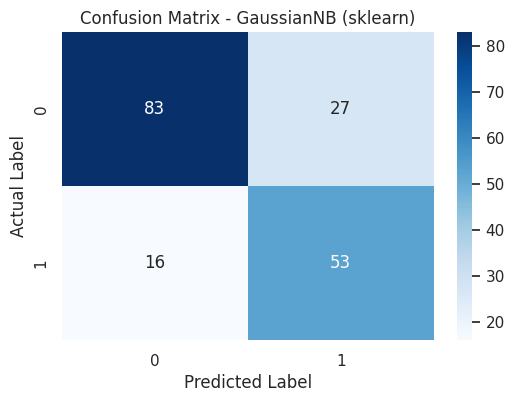

Classification Report - GaussianNB (sklearn):
              precision    recall  f1-score   support

           0       0.84      0.75      0.79       110
           1       0.66      0.77      0.71        69

    accuracy                           0.76       179
   macro avg       0.75      0.76      0.75       179
weighted avg       0.77      0.76      0.76       179



In [24]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# TODO: print accuracy_score for both y_pred_scratch and y_pred_sklearn
accuracy_scratch = accuracy_score(y_test, y_pred_scratch)
accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)

print("Gaussian Naive Bayes (Scratch) Accuracy:", accuracy_scratch)
print("Gaussian Naive Bayes (sklearn) Accuracy:", accuracy_sklearn)

# TODO: compute confusion_matrix for y_pred_sklearn and plot it with sns.heatmap(annot=True)
cm = confusion_matrix(y_test, y_pred_sklearn)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - GaussianNB (sklearn)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# TODO: print classification_report for y_pred_sklearn
print("Classification Report - GaussianNB (sklearn):")
print(classification_report(y_test, y_pred_sklearn))


**3.6 Final Comparison: Does All That Preprocessing Actually Help?**

Train one more `GaussianNB` on a **minimally processed** baseline (just impute missing `age`, drop other categorical columns) and compare its cross-validated accuracy to Member B's fully processed pipeline from Section 3.4.

In [25]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB

# TODO: build a quick baseline: X_baseline = titanic[['pclass','age','sibsp','parch','fare']] (imputed age only, no encoding/scaling/binning)
X_baseline = titanic[['pclass', 'age', 'sibsp', 'parch', 'fare']].copy()

# Impute missing age values
age_imputer = SimpleImputer(strategy='median')
X_baseline['age'] = age_imputer.fit_transform(X_baseline[['age']]).ravel()

# TODO: run the same cross_val_score(GaussianNB(), X_baseline, y, cv=5) on it
baseline_scores = cross_val_score(
    GaussianNB(),
    X_baseline,
    y,
    cv=5,
    scoring='accuracy'
)

# TODO: print both mean CV accuracies side-by-side and comment on the difference
baseline_mean = baseline_scores.mean()
processed_mean = cv_scores.mean()

print("Baseline CV accuracy:", baseline_mean)
print("Fully processed CV accuracy:", processed_mean)
print("Difference:", processed_mean - baseline_mean)

if processed_mean > baseline_mean:
    print("Comment: The fully processed features achieved higher mean CV accuracy.")
elif processed_mean < baseline_mean:
    print("Comment: The baseline achieved higher mean CV accuracy.")
else:
    print("Comment: Both approaches achieved the same mean CV accuracy.")

Baseline CV accuracy: 0.6768438892724876
Fully processed CV accuracy: 0.7669063331035162
Difference: 0.09006244383102857
Comment: The fully processed features achieved higher mean CV accuracy.


**Compare your 3 results:** from-scratch NB, `sklearn` NB on the full pipeline, and `sklearn` NB on the raw baseline. They should mostly agree in *direction* even if the exact numbers differ slightly.

#### **Wrap-Up: Group Reflection (Answer Together)**

As a group, discuss and write your answers in the cell below:

1. Which single preprocessing step from Part 2 do you think improved accuracy the most, and why?
2. How closely did your hand-computed Bayes' Theorem probability (Section 1.7) match the true empirical survival rate for women? If they didn't match exactly, why not?
3. Which Naive Bayes variant (`Gaussian`/`Multinomial`/`Bernoulli`/`Categorical`) would you choose for a spam-detection problem based on word counts, and why?
4. Why did we split the data into train/test **before** imputing, encoding, and scaling in Part 2, instead of doing it on the whole dataset first?

**1. Which single preprocessing step from Part 2 do you think improved accuracy the most, and why?**

The feature engineering steps, especially encoding categorical features such as `sex` and `embarked`, may have helped the model learn useful patterns. Our fully processed model achieved a mean cross-validation accuracy of **76.69%**, compared with **67.68%** for the baseline. However, we did not test each preprocessing step separately, so we cannot confirm which single step improved accuracy the most.

**2. How closely did your hand-computed Bayes' Theorem probability (Section 1.7) match the true empirical survival rate for women? If they didn't match exactly, why not?**

The hand-computed probability was approximately **74.2%**, which closely matched the empirical survival rate for women. Any small difference can occur because of rounding or calculation methods. Bayes' Theorem gives the same probability when exact counts are used.

**3. Which Naive Bayes variant (Gaussian/Multinomial/Bernoulli/Categorical) would you choose for a spam-detection problem based on word counts, and why?**

I would choose **Multinomial Naive Bayes** because it works well with word counts and text data. It calculates the probability of words appearing in spam and non-spam messages.

**4. Why did we split the data into train/test before imputing, encoding, and scaling in Part 2, instead of doing it on the whole dataset first?**

We split the data first to prevent data leakage. Imputers, encoders, and scalers should learn from the training data only. Then, the same learned transformations are applied to the test data. This gives a more reliable evaluation of the model on unseen data.